# Commodity analysis 
Analysing their correlations to each other and the UK energy prices. 

In [24]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

# 1. Define your multi-asset tickers dictionary
tickers = {
    "Brent Crude": "BZ=F",
    "Natural Gas": "NG=F",
    "Gold": "GC=F",
    "S&P 500": "^GSPC",
    "UK FTSE 100": "^FTSE",
}

# 2. Download historical 'Close' prices for all tickers in one go
data = yf.download(list(tickers.values()), start="2016-10-01", end="2026-10-13")[
    "Close"
]

# Rename columns to friendly names
data = data.rename(columns={v: k for k, v in tickers.items()})

# 3. Calculate Daily Log Returns for all assets
log_returns = np.log(data / data.shift(1)).dropna()

# 4. Generate the Cross-Asset Correlation Matrix
correlation_matrix = log_returns.corr()

print("--- Cross-Asset Correlation Matrix ---")
print(correlation_matrix.round(3))

# 5. Calculate Annualized Volatility (Standard Deviation * sqrt(252)) for each asset
annualized_volatility = log_returns.std() * np.sqrt(252)

print("\n--- Annualized Volatility (Risk) ---")
print(annualized_volatility.round(4))

/var/folders/m5/pl7f3qbs4wz97g9ld9_84ysw0000gn/T/ipykernel_59624/3732555596.py:16: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(list(tickers.values()), start="2016-10-01", end="2026-10-13")[
[*********************100%***********************]  5 of 5 completed

--- Cross-Asset Correlation Matrix ---
Ticker       Brent Crude   Gold  Natural Gas  UK FTSE 100  S&P 500
Ticker                                                            
Brent Crude        1.000  0.047        0.078        0.209    0.197
Gold               0.047  1.000        0.015        0.077    0.093
Natural Gas        0.078  0.015        1.000        0.032    0.075
UK FTSE 100        0.209  0.077        0.032        1.000    0.498
S&P 500            0.197  0.093        0.075        0.498    1.000

--- Annualized Volatility (Risk) ---
Ticker
Brent Crude    0.4056
Gold           0.1699
Natural Gas    0.6899
UK FTSE 100    0.1487
S&P 500        0.1824
dtype: float64


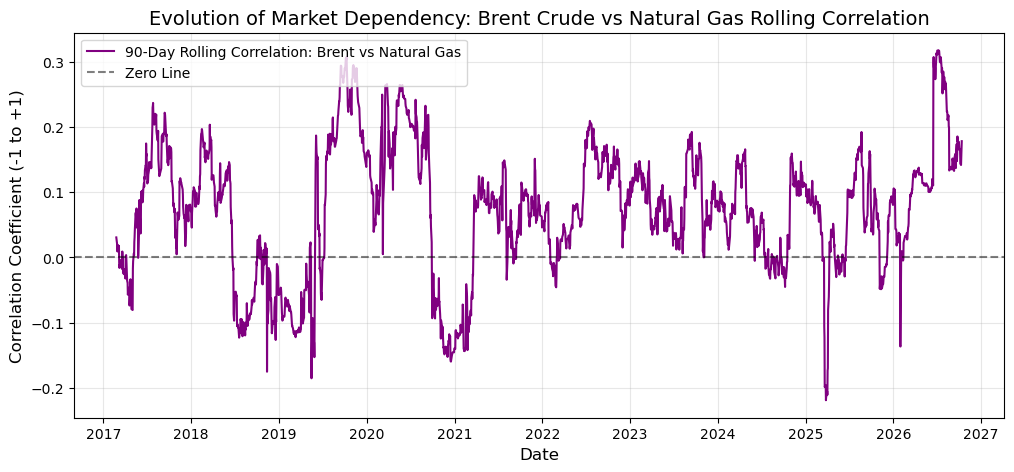

In [25]:
window_size = 90
rolling_corr = (
    log_returns["Brent Crude"]
    .rolling(window=window_size)
    .corr(log_returns["Natural Gas"])
)

# 5. Plot the rolling correlation over time
plt.figure(figsize=(12, 5))
plt.plot(
    rolling_corr.index,
    rolling_corr,
    label=f"{window_size}-Day Rolling Correlation: Brent vs Natural Gas",
    color="purple",
    linewidth=1.5,
)
plt.axhline(0, color="black", linestyle="--", alpha=0.5, label="Zero Line")
plt.title(
    "Evolution of Market Dependency: Brent Crude vs Natural Gas Rolling"
    " Correlation",
    fontsize=14,
)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Correlation Coefficient (-1 to +1)", fontsize=12)
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.show()

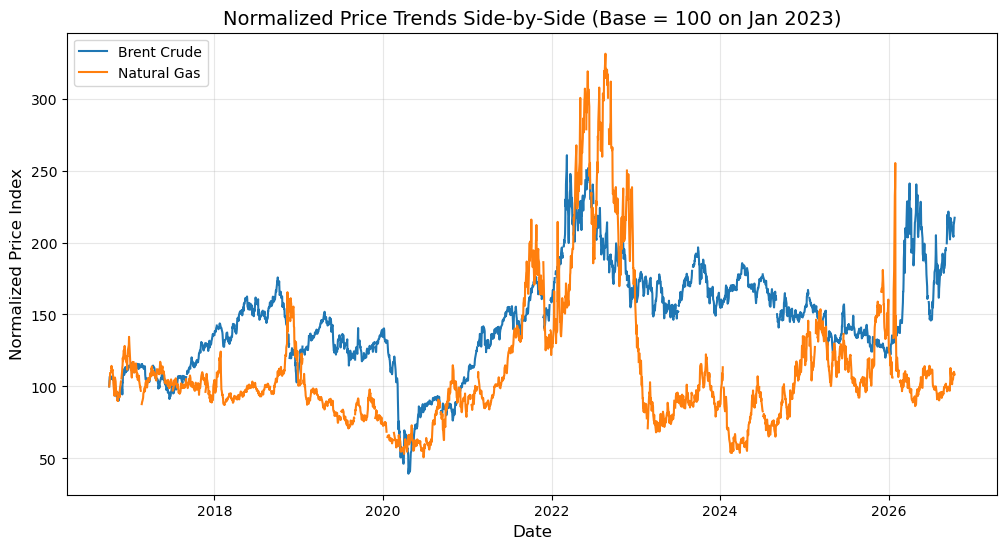

In [26]:
# 2. Normalize prices so they all start at 100 on the first day
normalized_data = (data / data.iloc[0]) * 100

normalized_data_Commodities = normalized_data[["Brent Crude", "Natural Gas"]]
# 3. Plot trends side-by-side
plt.figure(figsize=(12, 6))
for column in normalized_data_Commodities.columns:
  plt.plot(
      normalized_data_Commodities.index, normalized_data_Commodities[column], label=column, linewidth=1.5
  )

plt.title(
    "Normalized Price Trends Side-by-Side (Base = 100 on Jan 2023)", fontsize=14
)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Normalized Price Index", fontsize=12)
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.show()

Oil and gas are almost independent of each other, as the correlation is near zero, and they move in a different trend.  

In [27]:
import statsmodels.api as sm

# Drop any NaN rows
clean_returns = log_returns.dropna()

# Define X (independent variable: Brent Crude) and Y (dependent variable: Natural Gas)
X = clean_returns["Brent Crude"]
y = clean_returns["Natural Gas"]

# Add a constant to X (so the regression calculates an intercept / alpha)
X_with_const = sm.add_constant(X)

# Fit the Linear Regression model
reg_model = sm.OLS(y, X_with_const).fit()

# Print the regression summary
print(reg_model.summary())

                            OLS Regression Results                            
Dep. Variable:            Natural Gas   R-squared:                       0.006
Model:                            OLS   Adj. R-squared:                  0.006
Method:                 Least Squares   F-statistic:                     14.46
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           0.000147
Time:                        17:32:21   Log-Likelihood:                 4065.0
No. Observations:                2363   AIC:                            -8126.
Df Residuals:                    2361   BIC:                            -8115.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           0.0003      0.001      0.358      

In [28]:
import sys

!{sys.executable} -m pip install elexonpy


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [29]:
from datetime import datetime
import pandas as pd
from elexonpy.api.indicative_imbalance_settlement_api import (
    IndicativeImbalanceSettlementApi,
)
from elexonpy.api_client import ApiClient

# Initialize API client
api_client = ApiClient()
imbalance_settlement_api = IndicativeImbalanceSettlementApi(api_client)

# Fetch system prices data for a specific date
df_uk_power = (
    imbalance_settlement_api.balancing_settlement_system_prices_settlement_date_get(
        settlement_date="2026-10-10", format="dataframe"
    )
)

print(df_uk_power.head())

  settlement_date  settlement_period                start_time  \
0      2026-10-10                  1 2026-10-09 23:00:00+00:00   
1      2026-10-10                  2 2026-10-09 23:30:00+00:00   
2      2026-10-10                  3 2026-10-10 00:00:00+00:00   
3      2026-10-10                  4 2026-10-10 00:30:00+00:00   
4      2026-10-10                  5 2026-10-10 01:00:00+00:00   

          created_date_time  system_sell_price  system_buy_price  \
0 2026-10-10 23:44:29+00:00              44.76             44.76   
1 2026-10-11 00:14:35+00:00              39.61             39.61   
2 2026-10-11 00:45:00+00:00              57.45             57.45   
3 2026-10-11 01:14:32+00:00              70.00             70.00   
4 2026-10-11 01:44:30+00:00              47.56             47.56   

   bsad_defaulted price_derivation_code  reserve_scarcity_price  \
0           False                     N                     0.0   
1           False                     N                     

In [30]:
# 1. Ensure the settlement date column is converted to a proper datetime type
df_uk_power["date"] = pd.to_datetime(df_uk_power["settlement_date"])

# 2. Aggregate the 48 half-hourly prices into a single Daily Average price
# (Using system_sell_price as our primary benchmark)
daily_uk_power = (
    df_uk_power.groupby("date")["system_sell_price"].mean().reset_index()
)

# 3. Set the date as the index so it matches your Yahoo Finance time-series structure
daily_uk_power.set_index("date", inplace=True)

# Inspect your newly formatted daily UK power time series
print(daily_uk_power.head())

            system_sell_price
date                         
2026-10-10          82.238253


In [35]:
import matplotlib.pyplot as pd_plt  # alias to avoid naming conflicts
import pandas as pd
import yfinance as yf
from elexonpy.api.indicative_imbalance_settlement_api import (
    IndicativeImbalanceSettlementApi,
)
from elexonpy.api_client import ApiClient

# 1. Fetch Elexon data for a specific date range/day that matches your test
api_client = ApiClient()
imbalance_settlement_api = IndicativeImbalanceSettlementApi(api_client)

# Let's pull a specific target date that exists in your test window
df_uk_power = (
    imbalance_settlement_api.balancing_settlement_system_prices_settlement_date_get(
        settlement_date="2026-10-10", format="dataframe"
    )
)

# Convert Elexon data to daily average
df_uk_power["date"] = pd.to_datetime(df_uk_power["settlement_date"])
daily_uk_power = (
    df_uk_power.groupby("date")["system_sell_price"].mean().reset_index()
)
daily_uk_power.set_index("date", inplace=True)

# 2. Pull commodities specifically around that date window (e.g., October 2026)
tickers = {
    "Brent Crude": "BZ=F",
    "Natural Gas": "NG=F",
    "Gold": "GC=F",
    "S&P 500": "^GSPC",
}
commodity_data = yf.download(
    list(tickers.values()), start="2026-10-01", end="2026-10-13"
)["Close"]
commodity_data = commodity_data.rename(columns={v: k for k, v in tickers.items()})

# 3. Combine safely using an outer or inner join, checking rows first
master_df = commodity_data.copy()
master_df["UK Wholesale Power"] = daily_uk_power["system_sell_price"]

# Print row count to verify we have data before normalizing
print(
    f"Rows available after merge: {len(master_df.dropna())}"
)  # Ensures it's not zero

# Drop NAs only on the overlapping subset
master_clean = master_df.dropna()

if not master_clean.empty:
  # 4. Normalize and plot
  normalized_master = (master_clean / master_clean.iloc[0]) * 100

  pd_plt.figure(figsize=(12, 6))
  for column in normalized_master.columns:
    pd_plt.plot(
        normalized_master.index,
        normalized_master[column],
        label=column,
        linewidth=1.5,
    )

  pd_plt.title(
      "Multi-Asset Comparison: Global Commodities vs UK Wholesale Power (Base ="
      " 100)",
      fontsize=14,
  )
  pd_plt.xlabel("Date", fontsize=12)
  pd_plt.ylabel("Normalized Price Index", fontsize=12)
  pd_plt.legend(loc="upper left")
  pd_plt.grid(True, alpha=0.3)
  pd_plt.show()
else:
  print(
      "Warning: Date overlap resulted in 0 rows. Check your date ranges between"
      " Elexon and Yahoo Finance."
  )

/var/folders/m5/pl7f3qbs4wz97g9ld9_84ysw0000gn/T/ipykernel_59624/1672881320.py:34: FutureWarning: YF.download() has changed argument auto_adjust default to True
  commodity_data = yf.download(
[*********************100%***********************]  4 of 4 completed

Rows available after merge: 0


In [36]:
tickers = {
    "Brent Crude": "BZ=F",
    "Natural Gas": "NG=F",
    "Gold": "GC=F",
    "S&P 500": "^GSPC",
}
commodity_data = yf.download(
    list(tickers.values()), start="2026-01-01", end="2026-10-13"
)["Close"]
commodity_data = commodity_data.rename(columns={v: k for k, v in tickers.items()})

# 2. Combine your daily UK power data with the commodities into one master dataframe
master_df = commodity_data.copy()
master_df["UK Wholesale Power"] = daily_uk_power["system_sell_price"]

# Drop any rows where data doesn't align (e.g., weekends/holidays differences)
master_df = master_df.dropna()

# 3. Normalize everything to start at 100 on the first day
normalized_master = (master_df / master_df.iloc[0]) * 100

# 4. Plot them all together
plt.figure(figsize=(12, 6))
for column in normalized_master.columns:
    plt.plot(
        normalized_master.index,
        normalized_master[column],
        label=column,
        linewidth=1.5,
    )

plt.title(
    "Multi-Asset Comparison: Global Commodities vs UK Wholesale Power (Base ="
    " 100)",
    fontsize=14,
)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Normalized Price Index", fontsize=12)
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.show()

/var/folders/m5/pl7f3qbs4wz97g9ld9_84ysw0000gn/T/ipykernel_59624/4248291946.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  commodity_data = yf.download(
[*********************100%***********************]  4 of 4 completed


IndexError: single positional indexer is out-of-bounds